# Séparabilité de données circulaires

CSI4506 Introduction à l’intelligence artificielle

Marcel Turcotte (École de science informatique et de génie électrique,
Université d’Ottawa)  
2026-10-15

Ce cahier d’étude autonome prolonge la discussion de la présentation 11
sur les frontières de décision non linéaires. Nous comparons deux
manières d’obtenir une représentation utile : concevoir des attributs
pour la régression logistique et apprendre des représentations cachées
avec un réseau de neurones. Il complète le jeu de données circulaire de
<a href="https://playground.tensorflow.org" class="external"
data-icon="true">TensorFlow Playground</a>.

Les exemples Keras peuvent être explorés dès maintenant; les méthodes
d’entraînement, les pertes et les techniques de régularisation sont
développées dans les présentations 12 à 14.

## Données

Le cercle intérieur constitue la classe 1, et l’anneau extérieur, la
classe 0. Aucune droite ne peut séparer ces deux classes dans le plan
des entrées d’origine.

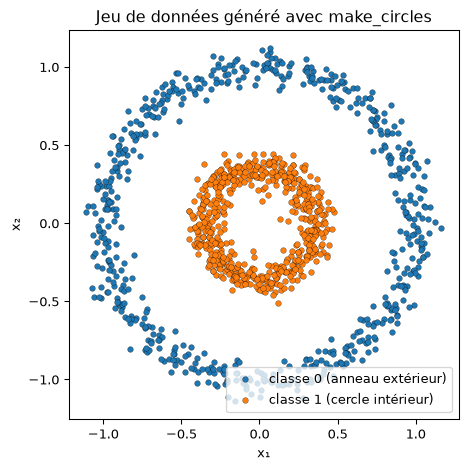

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

X_circles, y_circles = make_circles(
    n_samples=1200, factor=0.35, noise=0.06, random_state=42
)


def plot_samples(ax, X, y, labels=("classe 0", "classe 1")):
    for label in (0, 1):
        ax.scatter(
            X[y == label, 0], X[y == label, 1],
            color=f"C{label}", label=labels[label], s=18,
            edgecolor="k", linewidth=0.2,
        )
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.set_aspect("equal")
    ax.legend()


fig, ax = plt.subplots(figsize=(5, 5))
plot_samples(ax, X_circles, y_circles,
             labels=("classe 0 (anneau extérieur)",
                     "classe 1 (cercle intérieur)"))
ax.set_title("Jeu de données généré avec make_circles")
plt.tight_layout()
plt.show()

## Ingénierie des attributs

La régression logistique utilisant seulement $x_1$ et $x_2$ possède une
frontière de décision droite; elle ne peut donc pas séparer le cercle
intérieur de l’anneau qui l’entoure. Elle peut néanmoins produire une
frontière non linéaire dans le plan d’entrée si on lui fournit des
attributs non linéaires.

TensorFlow Playground propose $x_1^2$ et $x_2^2$ comme attributs
supplémentaires. Un réseau sans couche cachée avec une seule sortie
sigmoïde est une régression logistique sur les attributs sélectionnés.
Conserver les deux entrées d’origine et leurs carrés donne quatre
attributs; sélectionner seulement les carrés en donne deux.

Pour simplifier la visualisation, combinons les carrés des entrées en un
seul attribut :

$$
r = x_1^2 + x_2^2.
$$

Ici, $r$ désigne la **distance au carré depuis l’origine**, plutôt que
le rayon lui-même. Les points du cercle intérieur ont un petit $r$, et
ceux de l’anneau extérieur, un grand $r$. Élever la distance au carré
conserve leur ordre : il n’est donc pas nécessaire de calculer une
racine carrée.

Pour l’échantillon généré ci-dessus, les deux bandes sont séparées dans
l’espace $r$. Un seuil $r^*$ permet de séparer les classes :

$$
\text{intérieur si } r < r^*, \qquad \text{extérieur si } r > r^*.
$$

Ce même seuil correspond à un cercle dans le plan d’entrée d’origine.
Avec davantage de bruit, les bandes radiales peuvent se chevaucher et
une séparation parfaite peut devenir impossible.

## Ajuster un modèle dans l’espace r

Tous les modèles d’un jeu de données utilisent le même partitionnement :
60 % pour l’entraînement, 20 % pour la validation et 20 % pour le test.
Seuls les exemples d’entraînement servent à ajuster les paramètres. Le
réseau de neurones utilise la perte de validation pour l’arrêt précoce
(*early stopping*); les exemples de test sont réservés à la comparaison
finale.

In [3]:
def split_dataset(X, y):
    X_train, X_holdout, y_train, y_holdout = train_test_split(
        X, y, test_size=0.4, random_state=42, stratify=y
    )
    X_valid, X_test, y_valid, y_test = train_test_split(
        X_holdout, y_holdout, test_size=0.5,
        random_state=42, stratify=y_holdout,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test


def radial_features(X):
    return (X[:, 0]**2 + X[:, 1]**2).reshape(-1, 1)


X_train, X_valid, X_test, y_train, y_valid, y_test = split_dataset(
    X_circles, y_circles
)
r_circles = radial_features(X_circles)

clf_raw = LogisticRegression().fit(X_train, y_train)
clf_r = LogisticRegression().fit(radial_features(X_train), y_train)

w = clf_r.coef_[0, 0]
b = clf_r.intercept_[0]
r_threshold = -b / w
print(f"Seuil de décision : r* = {r_threshold:.3f}")

Seuil de décision : r* = 0.546

Le modèle radial estime $p(y=1\mid r)=\sigma(wr+b)$. Sa frontière de
décision vérifie $wr+b=0$, soit $r^*=-b/w$. Le poids appris est négatif
parce que la classe 1 occupe les plus petits rayons.

## Vue 3D

En associant à chaque point les coordonnées $(x_1,x_2,r)$, on transforme
la frontière de décision en un plan horizontal. Faites pivoter la vue
interactive pour voir comment ce plan sépare les deux bandes.

In [4]:
import plotly.graph_objects as go
from IPython.display import HTML, display

gx = np.linspace(X_circles[:, 0].min() - 0.2,
                 X_circles[:, 0].max() + 0.2, 30)
gy = np.linspace(X_circles[:, 1].min() - 0.2,
                 X_circles[:, 1].max() + 0.2, 30)
GX, GY = np.meshgrid(gx, gy)
GZ = np.full_like(GX, r_threshold)

plane = go.Surface(
    x=GX, y=GY, z=GZ, opacity=0.35, showscale=False,
    colorscale=[[0, "gray"], [1, "gray"]], hoverinfo="skip",
    name="plan de décision",
)
scatters = [
    go.Scatter3d(
        x=X_circles[y_circles == label, 0],
        y=X_circles[y_circles == label, 1],
        z=r_circles[y_circles == label, 0], mode="markers",
        marker=dict(size=3, color=color), name=name,
        hovertemplate=(
            "x₁=%{x:.3f}<br>x₂=%{y:.3f}<br>"
            "r=%{z:.3f}<extra></extra>"
        ),
    )
    for label, color, name in (
        (0, "#1f77b4", "classe 0 (anneau extérieur)"),
        (1, "#ff7f0e", "classe 1 (cercle intérieur)"),
    )
]
fig = go.Figure(data=[plane, *scatters])
fig.update_scenes(
    xaxis_title="x₁", yaxis_title="x₂", zaxis_title="r = x₁² + x₂²",
    aspectmode="cube", camera=dict(eye=dict(x=1.6, y=1.6, z=0.9)),
)
fig.update_layout(
    margin=dict(l=0, r=0, b=0, t=40),
    title=f"Plan de décision à r* ≈ {r_threshold:.3f}",
)
# Réutiliser le moteur mathématique du cahier sans charger une seconde copie.
display(HTML(fig.to_html(
    include_plotlyjs="cdn", include_mathjax=False, full_html=False
)))

La vue statique ci-dessous montre la même relation pour les lecteurs
dont l’outil de consultation du cahier ou l’exportation PDF n’affiche
pas les figures interactives.

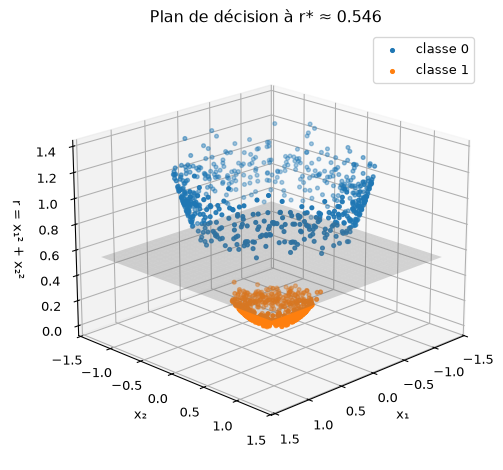

In [5]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(GX, GY, GZ, color="gray", alpha=0.25)
for label in (0, 1):
    ax.scatter(
        X_circles[y_circles == label, 0],
        X_circles[y_circles == label, 1],
        r_circles[y_circles == label, 0],
        color=f"C{label}", s=8, label=f"classe {label}",
    )
ax.set_xlabel("x₁")
ax.set_ylabel("x₂")
ax.set_zlabel("r = x₁² + x₂²")
ax.set_title(f"Plan de décision à r* ≈ {r_threshold:.3f}")
ax.view_init(elev=20, azim=45)
ax.legend()
plt.tight_layout()
plt.show()

## Séparabilité linéaire en 1D (espace r)

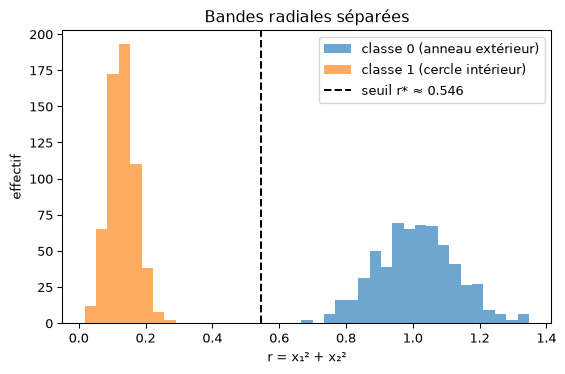

In [6]:
plt.figure(figsize=(6, 4))
bins = np.linspace(r_circles.min(), r_circles.max(), 40)
plt.hist(r_circles[y_circles == 0, 0], bins=bins, alpha=0.65,
         label="classe 0 (anneau extérieur)")
plt.hist(r_circles[y_circles == 1, 0], bins=bins, alpha=0.65,
         label="classe 1 (cercle intérieur)")
plt.axvline(r_threshold, linestyle="--", color="k",
            label=f"seuil r* ≈ {r_threshold:.3f}")
plt.xlabel("r = x₁² + x₂²")
plt.ylabel("effectif")
plt.title("Bandes radiales séparées")
plt.legend()
plt.tight_layout()
plt.show()

## Modèle logistique dans l’espace r en 1D

La probabilité de la classe 1 diminue lorsque la distance à l’origine
augmente. La ligne pointillée marque le seuil de probabilité de 0,5.

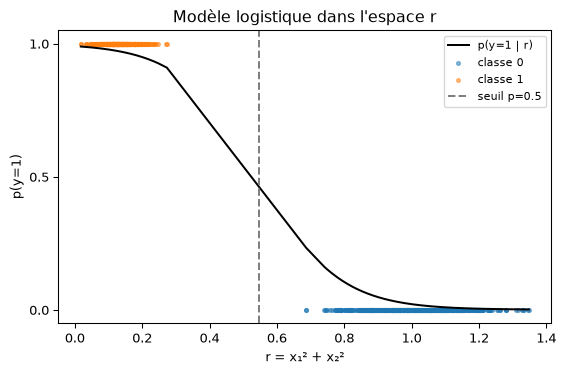

In [7]:
r_sorted = np.sort(r_circles[:, 0])
p_sorted = clf_r.predict_proba(r_sorted.reshape(-1, 1))[:, 1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r_sorted, p_sorted, color="k", label="p(y=1 | r)")
for label in (0, 1):
    positions = r_circles[y_circles == label, 0]
    ax.scatter(positions, np.full_like(positions, label),
               s=8, alpha=0.5, color=f"C{label}", label=f"classe {label}")
ax.axvline(r_threshold, linestyle="--", color="gray", label="seuil p=0.5")
ax.set_yticks([0, 0.5, 1])
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("r = x₁² + x₂²")
ax.set_ylabel("p(y=1)")
ax.set_title("Modèle logistique dans l'espace r")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Frontière de décision avec l’attribut radial

Les fonctions de tracé ci-dessous seront aussi utilisées pour le modèle
quadratique et les réseaux de neurones. Les couleurs du fond montrent la
probabilité estimée de la classe 1; le contour noir indique $p=0.5$. Les
points représentent l’ensemble des données générées, tandis que
l’ajustement des modèles utilise seulement la partition d’entraînement.

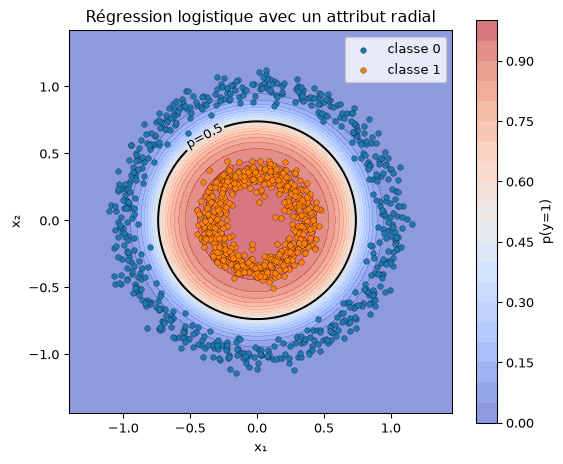

In [8]:
def make_grid(X):
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 300),
        np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 300),
    )
    return xx, yy, np.column_stack((xx.ravel(), yy.ravel()))


def plot_decision_boundary(xx, yy, probabilities, X, y, title):
    probabilities = probabilities.reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6, 5))
    shading = ax.contourf(xx, yy, probabilities,
                          levels=np.linspace(0, 1, 21),
                          cmap="coolwarm", alpha=0.6)
    boundary = ax.contour(xx, yy, probabilities, levels=[0.5], colors="k")
    ax.clabel(boundary, fmt={0.5: "p=0.5"})
    plot_samples(ax, X, y)
    ax.set_title(title)
    fig.colorbar(shading, ax=ax, label="p(y=1)")
    plt.tight_layout()
    plt.show()


xx, yy, grid = make_grid(X_circles)
p_r = clf_r.predict_proba(radial_features(grid))[:, 1]
plot_decision_boundary(xx, yy, p_r, X_circles, y_circles,
                       "Régression logistique avec un attribut radial")

## Frontière de décision avec les attributs quadratiques

<a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html"
class="external" data-icon="true"><code>PolynomialFeatures</code></a>,
avec un degré de 2 et sans colonne constante, produit cinq attributs :

$$
x_1,\quad x_2,\quad x_1^2,\quad x_1x_2,\quad x_2^2.
$$

Le modèle radial impose un coefficient commun aux carrés des entrées,
puisque $wr=w(x_1^2+x_2^2)$. Le modèle quadratique peut pondérer les
cinq attributs indépendamment. Les deux peuvent séparer ces cercles,
mais leurs frontières et leurs probabilités ajustées ne sont pas
nécessairement identiques. Leur régularisation par défaut agit aussi sur
des paramétrisations différentes.

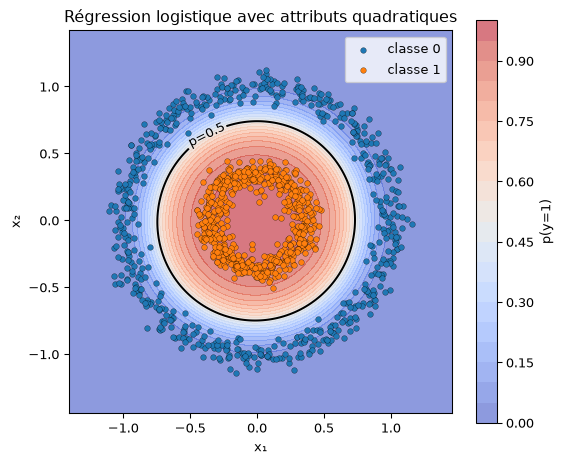

In [9]:
quad = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("logreg", LogisticRegression()),
]).fit(X_train, y_train)

p_quad = quad.predict_proba(grid)[:, 1]
plot_decision_boundary(xx, yy, p_quad, X_circles, y_circles,
                       "Régression logistique avec attributs quadratiques")

## Réseau de neurones

Le réseau de neurones reçoit uniquement les entrées d’origine $x_1$ et
$x_2$. Il possède **deux couches cachées** de quatre unités chacune,
suivies d’une seule sortie sigmoïde : trois couches avec des paramètres
entraînables. Les couches cachées utilisent `tanh`, une activation non
linéaire, et apprennent une représentation à partir des exemples
d’entraînement.

Il s’agit d’une configuration qui fonctionne, et non d’une affirmation
selon laquelle `tanh` s’entraîne toujours plus vite ou mieux que
d’autres activations. La réussite de l’entraînement dépend des données,
de l’initialisation, de l’architecture et des réglages de
l’optimisation.

In [10]:
from tensorflow import keras


def make_mlp():
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        keras.layers.Input(shape=(2,)),
        keras.layers.Dense(4, activation="tanh"),
        keras.layers.Dense(4, activation="tanh"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.01),
        loss="binary_crossentropy", metrics=["accuracy"],
    )
    return model


circle_mlp = make_mlp()

L’arrêt précoce surveille la perte de validation et restaure les poids
de l’époque où cette perte est la plus faible. Cette époque n’a pas
nécessairement la meilleure exactitude de validation. Nous évaluons donc
directement le modèle restauré, plutôt que de prendre des valeurs
provenant d’époques différentes dans l’historique d’entraînement. La
<a href="https://keras.io/api/callbacks/early_stopping/"
class="external" data-icon="true">documentation de Keras</a> explique
les paramètres de ce rappel (*callback*).

Époques exécutées : 300
Modèle restauré : exactitude d'entraînement = 1.000; exactitude de validation = 1.000

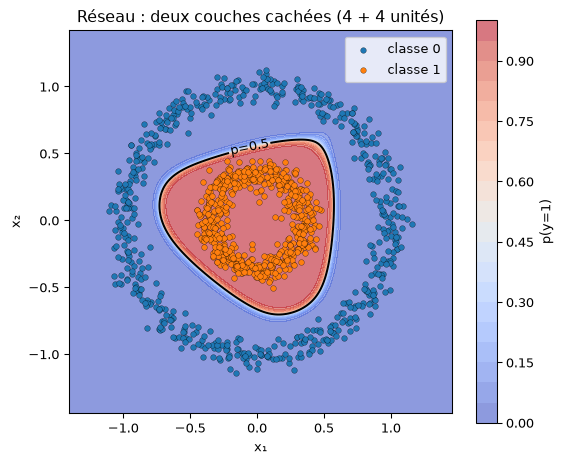

In [11]:
circle_history = circle_mlp.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=300, batch_size=64, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True,
    )],
)
_, train_accuracy = circle_mlp.evaluate(X_train, y_train, verbose=0)
_, valid_accuracy = circle_mlp.evaluate(X_valid, y_valid, verbose=0)
print(f"Époques exécutées : {len(circle_history.history['loss'])}")
print(f"Modèle restauré : exactitude d'entraînement = {train_accuracy:.3f}; "
      f"exactitude de validation = {valid_accuracy:.3f}")

p_mlp = circle_mlp.predict(grid, verbose=0).ravel()
plot_decision_boundary(xx, yy, p_mlp, X_circles, y_circles,
                       "Réseau : deux couches cachées (4 + 4 unités)")

### Évaluation finale sur l’ensemble de test des cercles

La comparaison utilise les mêmes exemples mis de côté pour tous les
modèles. Elle illustre l’effet de la représentation sur ce jeu de
données; une exécution réussie ne garantit pas les mêmes résultats avec
d’autres données ou réglages d’entraînement.

In [12]:
_, circle_test_accuracy = circle_mlp.evaluate(X_test, y_test, verbose=0)
circle_scores = {
    "Logistique : entrées d'origine": clf_raw.score(X_test, y_test),
    "Logistique : attribut radial": clf_r.score(
        radial_features(X_test), y_test
    ),
    "Logistique : attributs quadratiques": quad.score(X_test, y_test),
    "Réseau : entrées d'origine": circle_test_accuracy,
}
for name, accuracy in circle_scores.items():
    print(f"{name:<34} exactitude de test = {accuracy:.3f}")

Logistique : entrées d'origine     exactitude de test = 0.471
Logistique : attribut radial       exactitude de test = 1.000
Logistique : attributs quadratiques exactitude de test = 1.000
Réseau : entrées d'origine         exactitude de test = 1.000

## Jeu de données XOR

Dans la présentation 11, une couche cachée a été configurée à la main
pour calculer le XOR booléen. Ici, une version continue permet
d’explorer l’apprentissage d’une frontière non linéaire. Interprétez $A$
comme $(x_1>0)$ et $B$ comme $(x_2>0)$. La classe 1 correspond à
$A\oplus B$ : exactement une entrée est positive, ce qui donne les
quadrants supérieur gauche et inférieur droit.

Une frontière de décision droite ne peut pas séparer les classes dans le
plan d’origine. Des attributs conçus de manière appropriée et un réseau
de neurones sont deux moyens de surmonter cette limite.

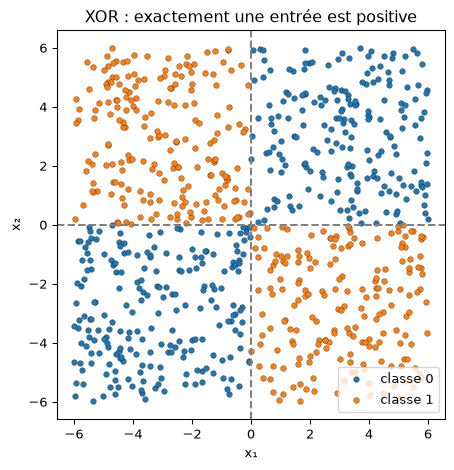

In [13]:
rng = np.random.default_rng(42)
X_xor = rng.uniform(-6, 6, size=(800, 2))
A = X_xor[:, 0] > 0
B = X_xor[:, 1] > 0
y_xor = np.logical_xor(A, B).astype(int)

fig, ax = plt.subplots(figsize=(5, 5))
plot_samples(ax, X_xor, y_xor)
ax.axhline(0, color="gray", linestyle="--")
ax.axvline(0, color="gray", linestyle="--")
ax.set_title("XOR : exactement une entrée est positive")
plt.tight_layout()
plt.show()

### L’attribut radial fonctionne-t-il encore?

L’attribut radial supprime l’information sur les signes. Des points à la
même distance de l’origine peuvent appartenir à l’une ou l’autre classe.
L’attribut qui séparait les cercles ne peut donc pas séparer XOR. Dans
cette distribution d’échantillonnage, l’étiquette est indépendante du
rayon au carré; un échantillon fini peut néanmoins présenter de petites
associations fortuites.

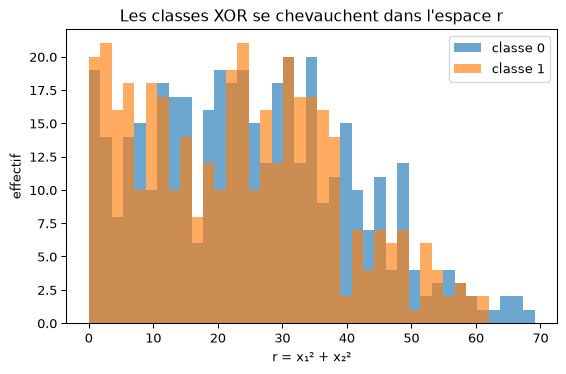

In [14]:
r_xor = radial_features(X_xor)
plt.figure(figsize=(6, 4))
bins = np.linspace(r_xor.min(), r_xor.max(), 40)
for label in (0, 1):
    plt.hist(r_xor[y_xor == label, 0], bins=bins, alpha=0.65,
             label=f"classe {label}")
plt.xlabel("r = x₁² + x₂²")
plt.ylabel("effectif")
plt.title("Les classes XOR se chevauchent dans l'espace r")
plt.legend()
plt.tight_layout()
plt.show()

### Un attribut qui conserve l’information pertinente

Le produit $s=x_1x_2$ distingue les signes opposés des signes
identiques. En dehors des axes de coordonnées, la classe 1 vérifie
$s<0$, et la classe 0, $s>0$. Un seuil nul sépare les classes dans cet
espace d’attributs.

Le développement quadratique comprend déjà $x_1x_2$. Le modèle
quadratique complet peut donc aussi représenter une frontière XOR, même
si l’attribut radial seul ne le permet pas.

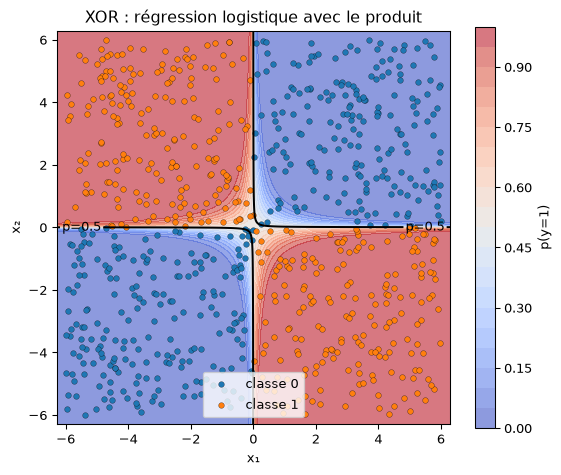

In [15]:
def product_features(X):
    return (X[:, 0] * X[:, 1]).reshape(-1, 1)


X_train, X_valid, X_test, y_train, y_valid, y_test = split_dataset(
    X_xor, y_xor
)
xor_raw = LogisticRegression().fit(X_train, y_train)
xor_radial = LogisticRegression().fit(radial_features(X_train), y_train)
xor_product = LogisticRegression().fit(product_features(X_train), y_train)
xor_quad = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("logreg", LogisticRegression()),
]).fit(X_train, y_train)

xx, yy, grid = make_grid(X_xor)
p_product = xor_product.predict_proba(product_features(grid))[:, 1]
plot_decision_boundary(xx, yy, p_product, X_xor, y_xor,
                       "XOR : régression logistique avec le produit")

### Apprendre à partir des entrées d’origine

Nous entraînons un nouveau réseau de neurones avec la même architecture
et les mêmes réglages que pour les cercles. Seules les entrées d’origine
sont fournies : nous ne donnons ni l’attribut radial ni le produit. La
fonction de tracé et la fonction de construction du modèle sont
réutilisées.

Époques exécutées : 126
Modèle restauré : exactitude d'entraînement = 1.000; exactitude de validation = 0.994

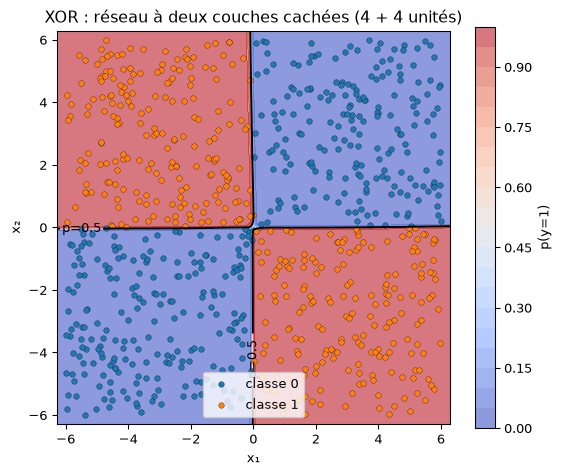

In [16]:
xor_mlp = make_mlp()
xor_history = xor_mlp.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=300, batch_size=64, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True,
    )],
)
_, train_accuracy = xor_mlp.evaluate(X_train, y_train, verbose=0)
_, valid_accuracy = xor_mlp.evaluate(X_valid, y_valid, verbose=0)
print(f"Époques exécutées : {len(xor_history.history['loss'])}")
print(f"Modèle restauré : exactitude d'entraînement = {train_accuracy:.3f}; "
      f"exactitude de validation = {valid_accuracy:.3f}")

p_mlp = xor_mlp.predict(grid, verbose=0).ravel()
plot_decision_boundary(xx, yy, p_mlp, X_xor, y_xor,
                       "XOR : réseau à deux couches cachées (4 + 4 unités)")

### Évaluation finale sur l’ensemble de test XOR

In [17]:
_, xor_test_accuracy = xor_mlp.evaluate(X_test, y_test, verbose=0)
xor_scores = {
    "Logistique : entrées d'origine": xor_raw.score(X_test, y_test),
    "Logistique : attribut radial": xor_radial.score(
        radial_features(X_test), y_test
    ),
    "Logistique : attribut produit": xor_product.score(
        product_features(X_test), y_test
    ),
    "Logistique : attributs quadratiques": xor_quad.score(X_test, y_test),
    "Réseau : entrées d'origine": xor_test_accuracy,
}
for name, accuracy in xor_scores.items():
    print(f"{name:<34} exactitude de test = {accuracy:.3f}")

Logistique : entrées d'origine     exactitude de test = 0.512
Logistique : attribut radial       exactitude de test = 0.556
Logistique : attribut produit      exactitude de test = 1.000
Logistique : attributs quadratiques exactitude de test = 0.988
Réseau : entrées d'origine         exactitude de test = 1.000

## À retenir

- La séparabilité linéaire dépend de la représentation. Un
  classificateur linéaire appliqué à des attributs non linéaires peut
  avoir une frontière non linéaire dans l’espace d’entrée d’origine.
- Les attributs utiles dépendent de la tâche : le rayon au carré sépare
  ces cercles, tandis que le produit distingue les quadrants de XOR.
- Les couches cachées fournissent un autre moyen d’apprendre une
  représentation. Elles ne garantissent ni que l’entraînement trouvera
  des paramètres appropriés, ni qu’un réseau surpassera un modèle doté
  d’attributs bien choisis.
- Ces expériences illustrent la distinction de la présentation 11 entre
  ce qu’une architecture peut représenter et ce qu’un entraînement
  trouve à partir de données.